## Cell 1 - Install and Imports

In [ ]:
!pip -q install -U --no-deps transformers huggingface-hub tokenizers safetensors accelerate evaluate rouge-score sacrebleu

In [1]:
# Important: do not upgrade or reinstall torch in Kaggle.
# A Torch/CUDA mismatch can cause: CUDA error: no kernel image is available for execution on the device.


import os, re, json, random, inspect, gc
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance

import torch
from torch.utils.data import Dataset, DataLoader

from transformers import (
    AutoTokenizer,
    ViTImageProcessor,
    VisionEncoderDecoderModel,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    default_data_collator,
    EarlyStoppingCallback,
)

try:
    from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
except Exception:
    corpus_bleu = None
    SmoothingFunction = None

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Torch:", torch.__version__)
print("Torch CUDA:", torch.version.cuda)
print("CUDA:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

Device: cuda
Torch: 2.10.0+cu128
Torch CUDA: 12.8
CUDA: Tesla T4


## Cell 2 - Configuration

In [3]:
ARABIC_CAPTION_CANDIDATES = [
    "/kaggle/input/datasets/mohamedmustafa/arabic-captions-for-flickr8k-dataset/Flickr8k_arabic_text.txt",
    "/kaggle/input/arabic-captions-for-flickr8k-dataset/Flickr8k_arabic_text.txt",
]

IMAGE_DIR_CANDIDATES = [
    "/kaggle/input/datasets/adityajn105/flickr8k/Images",
    "/kaggle/input/flickr8k/Images",
]

ENCODER_MODEL = "google/vit-base-patch16-224-in21k"
DECODER_MODEL = "aubmindlab/aragpt2-base"

MAX_TARGET_LEN = 36
TRAIN_EPOCHS = 4
BATCH_SIZE = 8
GRAD_ACCUM = 2
LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.01
GEN_NUM_BEAMS = 4

# Keep True for your project comparison. Set False if you want to test only the stronger baseline first.
RUN_ENHANCED_EXPERIMENT = True

# If Kaggle memory is limited, set BATCH_SIZE=4 and GRAD_ACCUM=4.
print("Effective batch size:", BATCH_SIZE * GRAD_ACCUM)

Effective batch size: 16


## Cell 3 - Load Arabic Captions

In [4]:
def find_path(candidates, fallback_name=None, is_dir=False):
    for p in candidates:
        p = Path(p)
        if p.exists():
            return p
    if fallback_name:
        matches = list(Path("/kaggle/input").rglob(fallback_name))
        matches = [m for m in matches if m.is_dir()] if is_dir else [m for m in matches if m.is_file()]
        if matches:
            return matches[0]
    raise FileNotFoundError(f"Could not find path. Tried: {candidates}")

ARABIC_CAPTIONS_FILE = find_path(ARABIC_CAPTION_CANDIDATES, "Flickr8k_arabic_text.txt")
IMAGE_DIR = find_path(IMAGE_DIR_CANDIDATES, "Images", is_dir=True)

print("Arabic captions:", ARABIC_CAPTIONS_FILE)
print("Image dir:", IMAGE_DIR)

def clean_arabic_text(text):
    text = str(text).strip()
    text = re.sub(r"[\u064B-\u065F\u0670\u0640]", "", text)
    text = re.sub(r"[\u0622\u0623\u0625]", "\u0627", text)
    text = re.sub(r"\u0649", "\u064A", text)
    text = re.sub(r"\u0624", "\u0648", text)
    text = re.sub(r"\u0626", "\u064A", text)
    text = re.sub(r"\u0629", "\u0647", text)
    text = re.sub(r"[^\u0600-\u06FF0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def parse_caption_file(path):
    rows = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if "	" in line:
                image_id, caption = line.split("	", 1)
            elif "," in line:
                image_id, caption = line.split(",", 1)
                if image_id.lower().strip() in {"image", "filename", "file_name"}:
                    continue
            else:
                parts = line.split(maxsplit=1)
                if len(parts) != 2:
                    continue
                image_id, caption = parts

            image_id = Path(image_id.replace("\\", "/").split("#")[0].strip()).name
            caption = clean_arabic_text(caption)
            if caption:
                rows.append((image_id, caption))
    return pd.DataFrame(rows, columns=["image_id", "caption"])

df = parse_caption_file(ARABIC_CAPTIONS_FILE)
df["image_path"] = df["image_id"].apply(lambda x: str(IMAGE_DIR / x))
df = df[df["image_path"].apply(os.path.exists)].drop_duplicates().reset_index(drop=True)

print(df.head())
print("Captions:", len(df))
print("Images:", df["image_id"].nunique())

Arabic captions: /kaggle/input/datasets/mohamedmustafa/arabic-captions-for-flickr8k-dataset/Flickr8k_arabic_text.txt
Image dir: /kaggle/input/datasets/adityajn105/flickr8k/Images
                    image_id  \
0  1000268201_693b08cb0e.jpg   
1  1000268201_693b08cb0e.jpg   
2  1000268201_693b08cb0e.jpg   
3  1001773457_577c3a7d70.jpg   
4  1001773457_577c3a7d70.jpg   

                                             caption  \
0                     طفله صغيره تتسلق الي مسرح خشبي   
1                  طفله صغيره تتسلق الدرج الي منزلها   
2   فتاه صغيره في ثوب وردي تذهب الي المقصوره الخشبيه   
3  كلب اسود وكلب ثلاثي الالوان يلعبان مع بعضهما ا...   
4  كلب اسود وكلب ابيض ببقع بنيه يحدقان في بعضهما ...   

                                          image_path  
0  /kaggle/input/datasets/adityajn105/flickr8k/Im...  
1  /kaggle/input/datasets/adityajn105/flickr8k/Im...  
2  /kaggle/input/datasets/adityajn105/flickr8k/Im...  
3  /kaggle/input/datasets/adityajn105/flickr8k/Im...  
4  /kaggle/input

## Cell 4 - Split by Image

In [5]:
image_ids = df["image_id"].drop_duplicates().sample(frac=1, random_state=SEED).tolist()

n = len(image_ids)
train_ids = set(image_ids[:int(0.80 * n)])
val_ids = set(image_ids[int(0.80 * n):int(0.90 * n)])
test_ids = set(image_ids[int(0.90 * n):])

train_df = df[df["image_id"].isin(train_ids)].reset_index(drop=True)
val_df = df[df["image_id"].isin(val_ids)].reset_index(drop=True)
test_df = df[df["image_id"].isin(test_ids)].reset_index(drop=True)

print("Train:", len(train_df), "captions |", train_df["image_id"].nunique(), "images")
print("Val:", len(val_df), "captions |", val_df["image_id"].nunique(), "images")
print("Test:", len(test_df), "captions |", test_df["image_id"].nunique(), "images")

Train: 19353 captions | 6472 images
Val: 2413 captions | 809 images
Test: 2418 captions | 810 images


## Cell 5 - Processor and Tokenizer

In [6]:
image_processor = ViTImageProcessor.from_pretrained(ENCODER_MODEL)
tokenizer = AutoTokenizer.from_pretrained(DECODER_MODEL)

specials = {}
if tokenizer.pad_token is None:
    specials["pad_token"] = "<pad>"
if tokenizer.bos_token is None:
    specials["bos_token"] = "<bos>"
if tokenizer.eos_token is None:
    specials["eos_token"] = "<eos>"
if specials:
    tokenizer.add_special_tokens(specials)

print("Tokenizer length:", len(tokenizer))
print("BOS:", tokenizer.bos_token, tokenizer.bos_token_id)
print("EOS:", tokenizer.eos_token, tokenizer.eos_token_id)
print("PAD:", tokenizer.pad_token, tokenizer.pad_token_id)

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizer length: 64000
BOS: <|endoftext|> 0
EOS: <|endoftext|> 0
PAD: <pad> 2


## Cell 6 - Dataset Classes

In [7]:
def enhance_pil_image(image):
    image = ImageOps.autocontrast(image)
    image = ImageEnhance.Contrast(image).enhance(1.22)
    image = ImageEnhance.Color(image).enhance(1.08)
    image = ImageEnhance.Sharpness(image).enhance(1.35)
    return image

class ArabicCaptionDataset(Dataset):
    def __init__(self, dataframe, image_processor, tokenizer, max_len=36, enhance=False):
        self.df = dataframe.reset_index(drop=True)
        self.image_processor = image_processor
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.enhance = enhance

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        if self.enhance:
            image = enhance_pil_image(image)

        pixel_values = self.image_processor(images=image, return_tensors="pt").pixel_values[0]

        target = row["caption"] + " " + self.tokenizer.eos_token
        labels = self.tokenizer(
            target,
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt",
        ).input_ids[0]

        labels[labels == self.tokenizer.pad_token_id] = -100
        return {"pixel_values": pixel_values, "labels": labels}

class ArabicCaptionEvalImageDataset(Dataset):
    def __init__(self, dataframe, image_processor, enhance=False):
        self.image_table = dataframe[["image_id", "image_path"]].drop_duplicates("image_id").reset_index(drop=True)
        self.image_processor = image_processor
        self.enhance = enhance

    def __len__(self):
        return len(self.image_table)

    def __getitem__(self, idx):
        row = self.image_table.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        if self.enhance:
            image = enhance_pil_image(image)
        pixel_values = self.image_processor(images=image, return_tensors="pt").pixel_values[0]
        return {"pixel_values": pixel_values, "image_id": row["image_id"], "image_path": row["image_path"]}

baseline_train_dataset = ArabicCaptionDataset(train_df, image_processor, tokenizer, MAX_TARGET_LEN, enhance=False)
baseline_val_dataset = ArabicCaptionDataset(val_df, image_processor, tokenizer, MAX_TARGET_LEN, enhance=False)

sample = baseline_train_dataset[0]
print(sample["pixel_values"].shape, sample["labels"].shape)

torch.Size([3, 224, 224]) torch.Size([36])


## Cell 7 - Build ViT + AraGPT2 Model

In [9]:
from transformers import AutoConfig

def build_model():
    decoder_config = AutoConfig.from_pretrained(DECODER_MODEL)
    decoder_config.is_decoder = True
    decoder_config.add_cross_attention = True
    decoder_config.bos_token_id = tokenizer.bos_token_id
    decoder_config.eos_token_id = tokenizer.eos_token_id
    decoder_config.pad_token_id = tokenizer.pad_token_id

    model = VisionEncoderDecoderModel.from_encoder_decoder_pretrained(
        ENCODER_MODEL,
        DECODER_MODEL,
        decoder_config=decoder_config,
    )

    model.decoder.resize_token_embeddings(len(tokenizer))

    model.config.decoder_start_token_id = tokenizer.bos_token_id
    model.config.eos_token_id = tokenizer.eos_token_id
    model.config.pad_token_id = tokenizer.pad_token_id
    model.config.decoder.vocab_size = len(tokenizer)
    model.config.vocab_size = len(tokenizer)

    model.generation_config.decoder_start_token_id = tokenizer.bos_token_id
    model.generation_config.eos_token_id = tokenizer.eos_token_id
    model.generation_config.pad_token_id = tokenizer.pad_token_id
    model.generation_config.max_length = MAX_TARGET_LEN
    model.generation_config.num_beams = GEN_NUM_BEAMS
    model.generation_config.no_repeat_ngram_size = 2

    # Stage choice: freeze the vision encoder at first. This usually improves stability on Flickr8k.
    for p in model.encoder.parameters():
        p.requires_grad = False

    return model

model_check = build_model()
print("Model parameters:", sum(p.numel() for p in model_check.parameters()) / 1e6, "M")
print("Trainable parameters:", sum(p.numel() for p in model_check.parameters() if p.requires_grad) / 1e6, "M")
del model_check
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: aubmindlab/aragpt2-base
Key                                                 | Status     | 
----------------------------------------------------+------------+-
h.{0...11}.attn.masked_bias                         | UNEXPECTED | 
h.{0...11}.attn.bias                                | UNEXPECTED | 
transformer.h.{0...11}.crossattention.q_attn.bias   | MISSING    | 
transformer.h.{0...11}.crossattention.c_proj.bias   | MISSING    | 
transformer.h.{0...11}.ln_cross_attn.bias           | MISSING    | 
transformer.h.{0...11}.crossattention.c_attn.bias   | MISSING    | 
transformer.h.{0...11}.crossattention.q_attn.weight | MISSING    | 
transformer.h.{0...11}.crossattention.c_proj.weight | MISSING    | 
transformer.h.{0...11}.ln_cross_attn.weight         | MISSING    | 
transformer.h.{0...11}.crossattention.c_attn.weight | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MIS

Model parameters: 249.750528 M
Trainable parameters: 163.36128 M


## Cell 8 - Training Arguments Helper

In [10]:
def make_training_args(output_dir):
    kwargs = dict(
        output_dir=output_dir,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        gradient_accumulation_steps=GRAD_ACCUM,
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        num_train_epochs=TRAIN_EPOCHS,
        save_strategy="epoch",
        logging_strategy="steps",
        logging_steps=100,
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        fp16=False,
        bf16=False,
        optim="adamw_torch",
        remove_unused_columns=False,
        report_to="none",
        dataloader_num_workers=2,
    )

    params = inspect.signature(Seq2SeqTrainingArguments.__init__).parameters
    if "eval_strategy" in params:
        kwargs["eval_strategy"] = "epoch"
    else:
        kwargs["evaluation_strategy"] = "epoch"

    return Seq2SeqTrainingArguments(**kwargs)

## Cell 9 - Train One Transformer Experiment

In [11]:
def train_transformer_experiment(name, enhance=False):
    print("" + "=" * 80)
    print("Training:", name, "| enhance=", enhance)
    print("=" * 80)

    train_dataset = ArabicCaptionDataset(train_df, image_processor, tokenizer, MAX_TARGET_LEN, enhance=enhance)
    val_dataset = ArabicCaptionDataset(val_df, image_processor, tokenizer, MAX_TARGET_LEN, enhance=enhance)

    model = build_model()
    args = make_training_args(f"/kaggle/working/{name}")

    trainer = Seq2SeqTrainer(
        model=model,
        args=args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        data_collator=default_data_collator,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )

    trainer.train()
    trainer.save_model(f"/kaggle/working/{name}_best")
    tokenizer.save_pretrained(f"/kaggle/working/{name}_best")

    return model, trainer

baseline_model, baseline_trainer = train_transformer_experiment(
    "vit_aragpt2_without_enhancement",
    enhance=False,
)

Training: vit_aragpt2_without_enhancement | enhance= False


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: aubmindlab/aragpt2-base
Key                                                 | Status     | 
----------------------------------------------------+------------+-
h.{0...11}.attn.masked_bias                         | UNEXPECTED | 
h.{0...11}.attn.bias                                | UNEXPECTED | 
transformer.h.{0...11}.crossattention.q_attn.bias   | MISSING    | 
transformer.h.{0...11}.crossattention.c_proj.bias   | MISSING    | 
transformer.h.{0...11}.ln_cross_attn.bias           | MISSING    | 
transformer.h.{0...11}.crossattention.c_attn.bias   | MISSING    | 
transformer.h.{0...11}.crossattention.q_attn.weight | MISSING    | 
transformer.h.{0...11}.crossattention.c_proj.weight | MISSING    | 
transformer.h.{0...11}.ln_cross_attn.weight         | MISSING    | 
transformer.h.{0...11}.crossattention.c_attn.weight | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MIS

Epoch,Training Loss,Validation Loss
1,11.640017,5.308124
2,10.150419,5.016810
3,9.471912,4.898323
4,8.869930,4.868191


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['decoder.lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Cell 10 - Optional Enhanced Experiment

In [12]:
if RUN_ENHANCED_EXPERIMENT:
    enhanced_model, enhanced_trainer = train_transformer_experiment(
        "vit_aragpt2_with_enhancement",
        enhance=True,
    )
else:
    enhanced_model, enhanced_trainer = None, None

Training: vit_aragpt2_with_enhancement | enhance= True


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: aubmindlab/aragpt2-base
Key                                                 | Status     | 
----------------------------------------------------+------------+-
h.{0...11}.attn.masked_bias                         | UNEXPECTED | 
h.{0...11}.attn.bias                                | UNEXPECTED | 
transformer.h.{0...11}.crossattention.q_attn.bias   | MISSING    | 
transformer.h.{0...11}.crossattention.c_proj.bias   | MISSING    | 
transformer.h.{0...11}.ln_cross_attn.bias           | MISSING    | 
transformer.h.{0...11}.crossattention.c_attn.bias   | MISSING    | 
transformer.h.{0...11}.crossattention.q_attn.weight | MISSING    | 
transformer.h.{0...11}.crossattention.c_proj.weight | MISSING    | 
transformer.h.{0...11}.ln_cross_attn.weight         | MISSING    | 
transformer.h.{0...11}.crossattention.c_attn.weight | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MIS

Epoch,Training Loss,Validation Loss
1,11.640891,5.300254
2,10.159667,5.014587
3,9.472238,4.892319
4,8.870992,4.862433


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['decoder.lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Cell 11 - Honest Masked Token Accuracy

In [19]:
@torch.no_grad()
def teacher_forced_token_accuracy(model, dataframe, enhance=False, max_batches=None):
    dataset = ArabicCaptionDataset(dataframe, image_processor, tokenizer, MAX_TARGET_LEN, enhance=enhance)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=default_data_collator)

    model.to(device)
    model.eval()
    correct = 0
    total = 0

    for step, batch in enumerate(loader):
        if max_batches is not None and step >= max_batches:
            break
        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)
        outputs = model(pixel_values=pixel_values, labels=labels)
        preds = torch.argmax(outputs.logits, dim=-1)
        mask = labels != -100
        correct += ((preds == labels) & mask).sum().item()
        total += mask.sum().item()

    return correct / max(total, 1)

baseline_val_acc = teacher_forced_token_accuracy(baseline_model, val_df, enhance=False)
print("Baseline masked validation token accuracy:", baseline_val_acc)

if RUN_ENHANCED_EXPERIMENT:
    enhanced_val_acc = teacher_forced_token_accuracy(enhanced_model, val_df, enhance=True)
    print("Enhanced masked validation token accuracy:", enhanced_val_acc)

Baseline masked validation token accuracy: 0.5337177152876121
Enhanced masked validation token accuracy: 0.5280194214040057


## Cell 12 - BLEU Generation Evaluation

In [21]:
def collate_eval_batch(batch):
    return {
        "pixel_values": torch.stack([item["pixel_values"] for item in batch]),
        "image_ids": [item["image_id"] for item in batch],
        "image_paths": [item["image_path"] for item in batch],
    }

@torch.no_grad()
def generate_predictions(model, dataframe, enhance=False, batch_size=12):
    eval_dataset = ArabicCaptionEvalImageDataset(dataframe, image_processor, enhance=enhance)
    loader = DataLoader(eval_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_eval_batch)

    model.to(device)
    model.eval()
    pred_map = {}

    for batch in loader:
        pixel_values = batch["pixel_values"].to(device)
        generated = model.generate(
            pixel_values=pixel_values,
            max_length=MAX_TARGET_LEN,
            num_beams=GEN_NUM_BEAMS,
            no_repeat_ngram_size=2,
            early_stopping=True,
        )
        preds = tokenizer.batch_decode(generated, skip_special_tokens=True)
        for image_id, pred in zip(batch["image_ids"], preds):
            pred_map[image_id] = clean_arabic_text(pred)

    return pred_map

def bleu_scores_from_predictions(pred_map, dataframe, experiment_name):
    image_ids = dataframe["image_id"].drop_duplicates().tolist()
    references, hypotheses = [], []

    for image_id in image_ids:
        refs = dataframe[dataframe["image_id"] == image_id]["caption"].tolist()
        references.append([r.split() for r in refs])
        hypotheses.append(pred_map.get(image_id, "").split())

    if corpus_bleu is None:
        return {"experiment": experiment_name}

    smoothie = SmoothingFunction().method4
    return {
        "experiment": experiment_name,
        "BLEU-1": corpus_bleu(references, hypotheses, weights=(1, 0, 0, 0), smoothing_function=smoothie),
        "BLEU-2": corpus_bleu(references, hypotheses, weights=(0.5, 0.5, 0, 0), smoothing_function=smoothie),
        "BLEU-3": corpus_bleu(references, hypotheses, weights=(1/3, 1/3, 1/3, 0), smoothing_function=smoothie),
        "BLEU-4": corpus_bleu(references, hypotheses, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothie),
    }

baseline_pred_map = generate_predictions(baseline_model, test_df, enhance=False)
baseline_scores = bleu_scores_from_predictions(
    baseline_pred_map,
    test_df,
    "vit_aragpt2_without_enhancement",
)
baseline_scores["val_masked_token_accuracy"] = baseline_val_acc

all_scores = [baseline_scores]

if RUN_ENHANCED_EXPERIMENT:
    enhanced_pred_map = generate_predictions(enhanced_model, test_df, enhance=True)
    enhanced_scores = bleu_scores_from_predictions(
        enhanced_pred_map,
        test_df,
        "vit_aragpt2_with_enhancement",
    )
    enhanced_scores["val_masked_token_accuracy"] = enhanced_val_acc
    all_scores.append(enhanced_scores)

results = pd.DataFrame(all_scores)
print(results)

results.to_csv("/kaggle/working/vit_aragpt2_transformer_results.csv", index=False)
with open("/kaggle/working/vit_aragpt2_transformer_results.json", "w", encoding="utf-8") as f:
    json.dump(results.to_dict(orient="records"), f, ensure_ascii=False, indent=2)

print("Saved: /kaggle/working/vit_aragpt2_transformer_results.csv")

                        experiment    BLEU-1    BLEU-2    BLEU-3    BLEU-4  \
0  vit_aragpt2_without_enhancement  0.407308  0.271068  0.175489  0.113429   
1     vit_aragpt2_with_enhancement  0.407366  0.268120  0.168009  0.103608   

   val_masked_token_accuracy  
0                   0.533718  
1                   0.528019  
Saved: /kaggle/working/vit_aragpt2_transformer_results.csv


## Cell 13 - Sample Predictions

ViT + AraGPT2 Samples - Without Enhancement


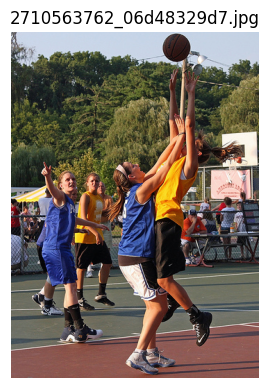

Prediction: لاعب كره سله يرتدي قميصا احمر اللون يلعب كره السله
References:
- لاعبو كره السله يقفزون لالتقاط الكره خلال المباراه
- تلعب الفتيات كره السله
- فريقان من لاعبي كره السله يلعبون في ملعب خارجي



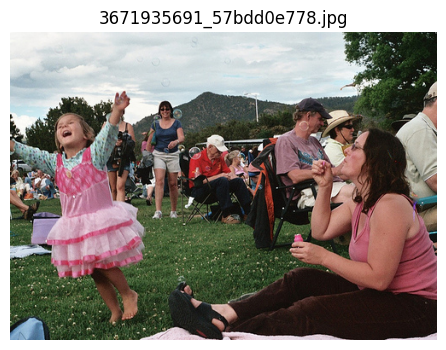

Prediction: فتاه صغيره تجلس علي مقعد في الحديقه
References:
- امراه تهب فقاعات وفتاه صغيره في ثوب وردي تلعب امامها
- طفل صغير يحاول التقاط فقاعات تهبها امراه تجاهه
- فتاه صغيره في ثوب وردي ترقص بينما امراه تنفخ فقاعات



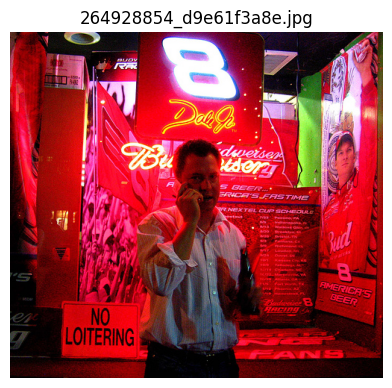

Prediction: رجل يجلس علي طاوله في مطعم
References:
- رجل يتحدث علي الهاتف المحمول خارج الخماره
- رجل يتحدث علي الهاتف امام لافته النيون
- الرجل يتحدث علي هاتفه المحمول امام متجر رياضي



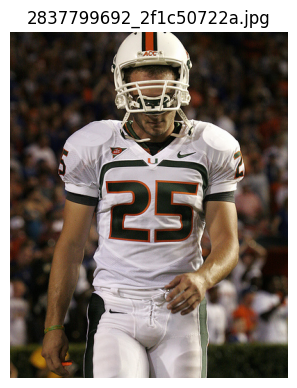

Prediction: اثنين من لاعبي كره القدم يرتدون الزي الاحمر والابيض
References:
- لاعب كره القدم ذو الرقم 25
- لاعب كره قدم ، يرتدي خوذته ، ينظر الي الارض
- لاعب كره قدم يرتدي لباس ابيض منتظم وينظر الي الاسفل



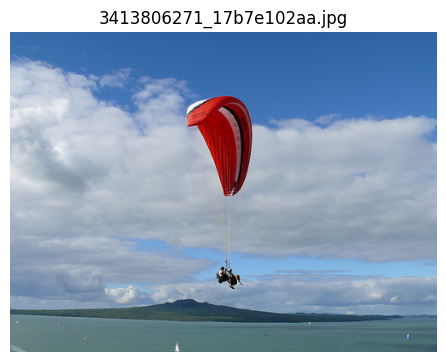

Prediction: رجل يقفز في الهواء فوق الماء
References:
- الناس في البركه الحمراء تنزلق فوق الماء
- شخصان مربوطان يطيران بمظله حمراء كبيره
- شخصان يتدليان من طايره شراعيه حمراء وبيضاء وسوداء مع سحاب ازرق غايم خلفهما



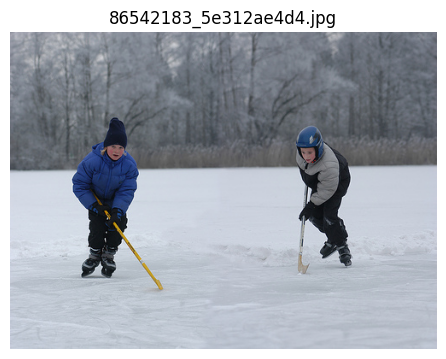

Prediction: مجموعه من الناس يلعبون لعبه الهوكي في الثلج
References:
- صبيان يلعبان الهوكي علي بركه مجمده
- طفلين يلعبان لعبه الهوكي في الثلج
- طفلين يلعبان لعبه الهوكي علي بركه



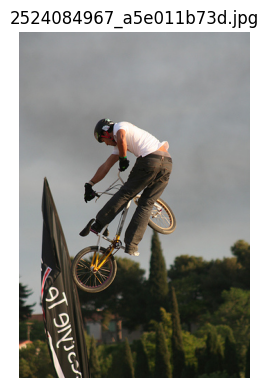

Prediction: راكب الدراجه الناريه يقوم بخدعه علي منحدر
References:
- رجل يقوم بخدعه دراجه هواييه في الجو
- رجل يرتدي قميصا ابيض اللون يقفز علي دراجه صفراء
- الرجل يقوم بخدعه قباله منحدر مع دراجه هواييه



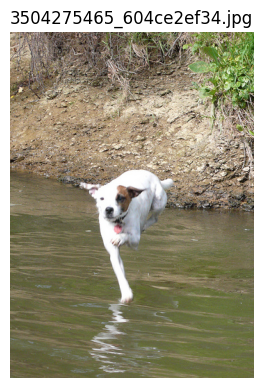

Prediction: كلب ابيض واسود يقفز في الماء
References:
- كلب ابيض يجري في النهر
- كلب ابيض يركض في بحيره
- كلب ابيض مع علامات البني يقفز في الماء

ViT + AraGPT2 Samples - With Enhancement


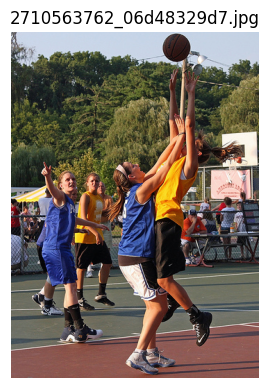

Prediction: مجموعه من لاعبي كره السله في الملعب
References:
- لاعبو كره السله يقفزون لالتقاط الكره خلال المباراه
- تلعب الفتيات كره السله
- فريقان من لاعبي كره السله يلعبون في ملعب خارجي



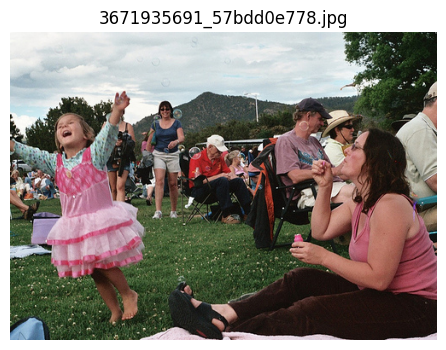

Prediction: مجموعه من الناس يجلسون علي طاوله في الهواء الطلق
References:
- امراه تهب فقاعات وفتاه صغيره في ثوب وردي تلعب امامها
- طفل صغير يحاول التقاط فقاعات تهبها امراه تجاهه
- فتاه صغيره في ثوب وردي ترقص بينما امراه تنفخ فقاعات



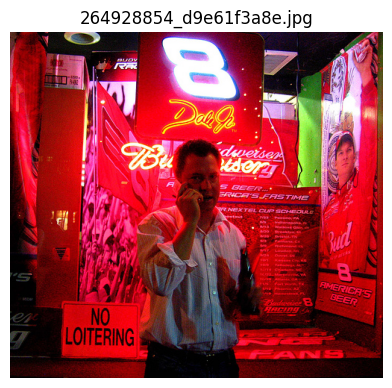

Prediction: رجل يجلس علي طاوله في الهواء الطلق
References:
- رجل يتحدث علي الهاتف المحمول خارج الخماره
- رجل يتحدث علي الهاتف امام لافته النيون
- الرجل يتحدث علي هاتفه المحمول امام متجر رياضي



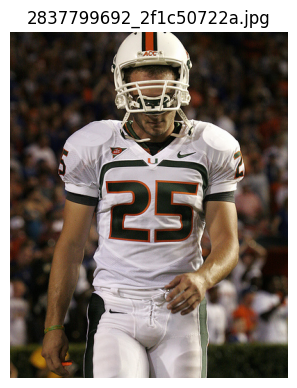

Prediction: لاعب كره قدم يرتدي قميصا احمر اللون يلعب كره القدم
References:
- لاعب كره القدم ذو الرقم 25
- لاعب كره قدم ، يرتدي خوذته ، ينظر الي الارض
- لاعب كره قدم يرتدي لباس ابيض منتظم وينظر الي الاسفل



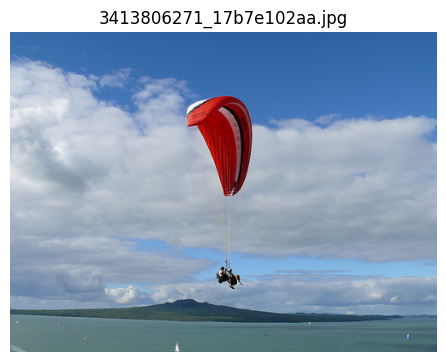

Prediction: رجل يرتدي قميصا ازرق وقبعه بيضاء يقفز في الهواء فوق الماء
References:
- الناس في البركه الحمراء تنزلق فوق الماء
- شخصان مربوطان يطيران بمظله حمراء كبيره
- شخصان يتدليان من طايره شراعيه حمراء وبيضاء وسوداء مع سحاب ازرق غايم خلفهما



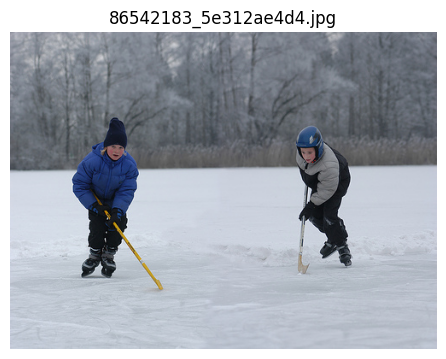

Prediction: شخصان يلعبان لعبه الهوكي
References:
- صبيان يلعبان الهوكي علي بركه مجمده
- طفلين يلعبان لعبه الهوكي في الثلج
- طفلين يلعبان لعبه الهوكي علي بركه



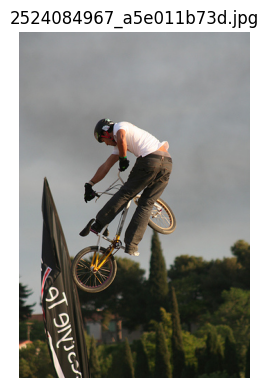

Prediction: راكب الدراجه الناريه يقوم بخدعه علي دراجته
References:
- رجل يقوم بخدعه دراجه هواييه في الجو
- رجل يرتدي قميصا ابيض اللون يقفز علي دراجه صفراء
- الرجل يقوم بخدعه قباله منحدر مع دراجه هواييه



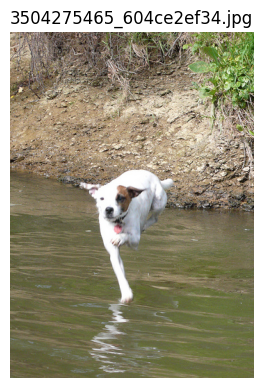

Prediction: كلب ابيض واسود يقفز في الماء
References:
- كلب ابيض يجري في النهر
- كلب ابيض يركض في بحيره
- كلب ابيض مع علامات البني يقفز في الماء



In [15]:
def show_prediction_samples(pred_map, dataframe, title, n=8):
    print("" + "=" * 80)
    print(title)
    print("=" * 80)

    sample = dataframe[["image_id", "image_path"]].drop_duplicates("image_id").sample(
        n=min(n, dataframe["image_id"].nunique()),
        random_state=SEED,
    )

    for _, row in sample.iterrows():
        image_id = row["image_id"]
        refs = dataframe[dataframe["image_id"] == image_id]["caption"].tolist()[:5]
        pred = pred_map.get(image_id, "")

        img = plt.imread(row["image_path"])
        plt.figure(figsize=(5.5, 4.5))
        plt.imshow(img)
        plt.axis("off")
        plt.title(image_id)
        plt.show()

        print("Prediction:", pred)
        print("References:")
        for ref in refs:
            print("-", ref)
        print()

show_prediction_samples(
    baseline_pred_map,
    test_df,
    "ViT + AraGPT2 Samples - Without Enhancement",
    n=8,
)

if RUN_ENHANCED_EXPERIMENT:
    show_prediction_samples(
        enhanced_pred_map,
        test_df,
        "ViT + AraGPT2 Samples - With Enhancement",
        n=8,
    )

## Cell 14 - Best Model Summary

In [22]:
best_row = results.sort_values("BLEU-4", ascending=False).iloc[0] if "BLEU-4" in results.columns else results.iloc[0]
print("Best model based on BLEU-4:")
print(best_row)
print()
print("Saved outputs:")
print("/kaggle/working/vit_aragpt2_transformer_results.csv")
print("/kaggle/working/vit_aragpt2_transformer_results.json")
print("/kaggle/working/vit_aragpt2_without_enhancement_best")
if RUN_ENHANCED_EXPERIMENT:
    print("/kaggle/working/vit_aragpt2_with_enhancement_best")

Best model based on BLEU-4:
experiment                   vit_aragpt2_without_enhancement
BLEU-1                                              0.407308
BLEU-2                                              0.271068
BLEU-3                                              0.175489
BLEU-4                                              0.113429
val_masked_token_accuracy                           0.533718
Name: 0, dtype: object

Saved outputs:
/kaggle/working/vit_aragpt2_transformer_results.csv
/kaggle/working/vit_aragpt2_transformer_results.json
/kaggle/working/vit_aragpt2_without_enhancement_best
/kaggle/working/vit_aragpt2_with_enhancement_best
